In [2]:
import os, torch
os.chdir('/home/ubuntu/BackTime')
import numpy as np
from dataset import load_raw_data

/home/ubuntu/BackTime/backtime/lib/python3.7/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


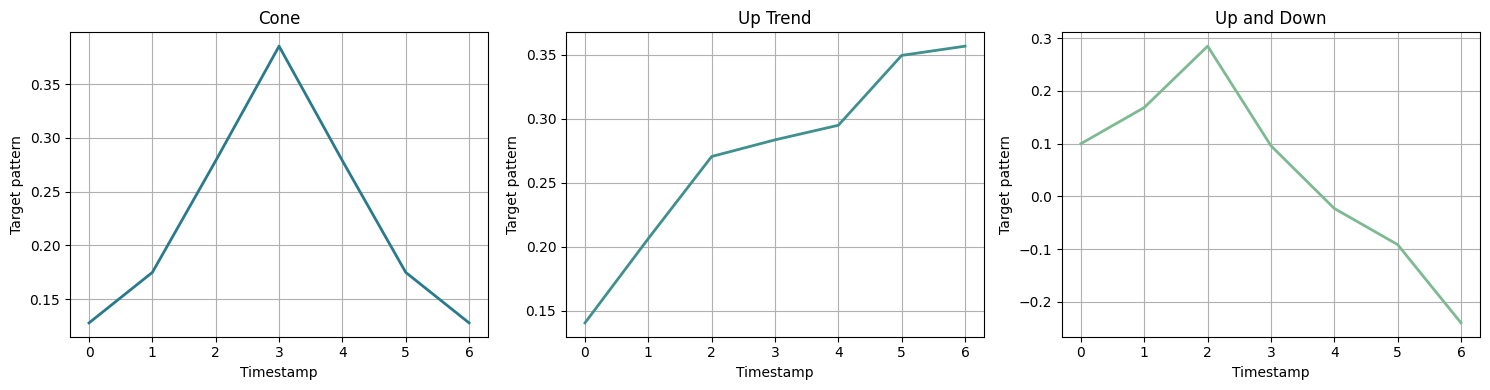

In [7]:
#@pattern
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cone =  np.array([0.1278, 0.1748, 0.2787, 0.3853, 0.2787, 0.1748, 0.1278])
up_trend = np.array([0.1405, 0.2064, 0.2705, 0.2835, 0.2949, 0.3495, 0.3567])
up_and_down = np.array([0.10, 0.1687, 0.2851, 0.09601, -0.0230, -0.0916, -0.2402])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = sns.color_palette("crest")
arrays = [cone, up_trend, up_and_down]
titles = ["Cone", "Up Trend", "Up and Down"]
colors = [palette[3], palette[2], palette[0]]  # Using crest palette colors
for ax, arr, title, color in zip(axes, arrays, titles, colors):
    sns.lineplot(ax=ax, x=np.arange(len(arr)), y=arr, color=color, linewidth=2)
    ax.set_title(title)
    ax.grid(True)
    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Target pattern")
plt.tight_layout()
plt.show()

# PEMS03

## Load config

In [3]:
from run import parser_args
from pprint import pprint
config = parser_args()
pprint(config)

{'Dataset': {'data_filename': './data/PEMS03/PEMS03.npz',
             'dataset_name': 'PEMS03',
             'len_input': 12,
             'num_for_predict': 12,
             'num_of_vertices': 358,
             'period': 288,
             'points_per_hour': 12,
             'use_timestamps': False},
 'Model': {'activation': 'gelu',
           'c_out': 358,
           'd_ff': 2048,
           'd_layers': 1,
           'd_model': 512,
           'dec_in': 358,
           'distil': 1,
           'dropout': 0.1,
           'e_layers': 2,
           'embed': 'timeF',
           'enc_in': 358,
           'factor': 3,
           'freq': 'h',
           'label_len': 12,
           'moving_avg': 25,
           'n_heads': 8,
           'num_kernels': 6,
           'output_attention': 0,
           'pred_len': 12,
           'seq_len': 12,
           'task_name': 'short_term_forecast'},
 'Surrogate': {'activation': 'gelu',
               'c_out': 358,
               'd_ff': 2048,
              

In [4]:
data_config = config.Dataset
if not data_config.use_timestamps:
    train_mean, train_std, train_data_seq, test_data_seq = load_raw_data(data_config)
    train_data_stamps = test_data_stamps = None
else:
    train_mean, train_std, train_data_seq, test_data_seq, train_data_stamps, test_data_stamps = load_raw_data(data_config)

train_mean, train_std, train_data_seq.shape, test_data_seq.shape

(181.38544768059074, 144.40621769174342, (15724, 358, 1), (5242, 358, 1))

## Benign data analysis

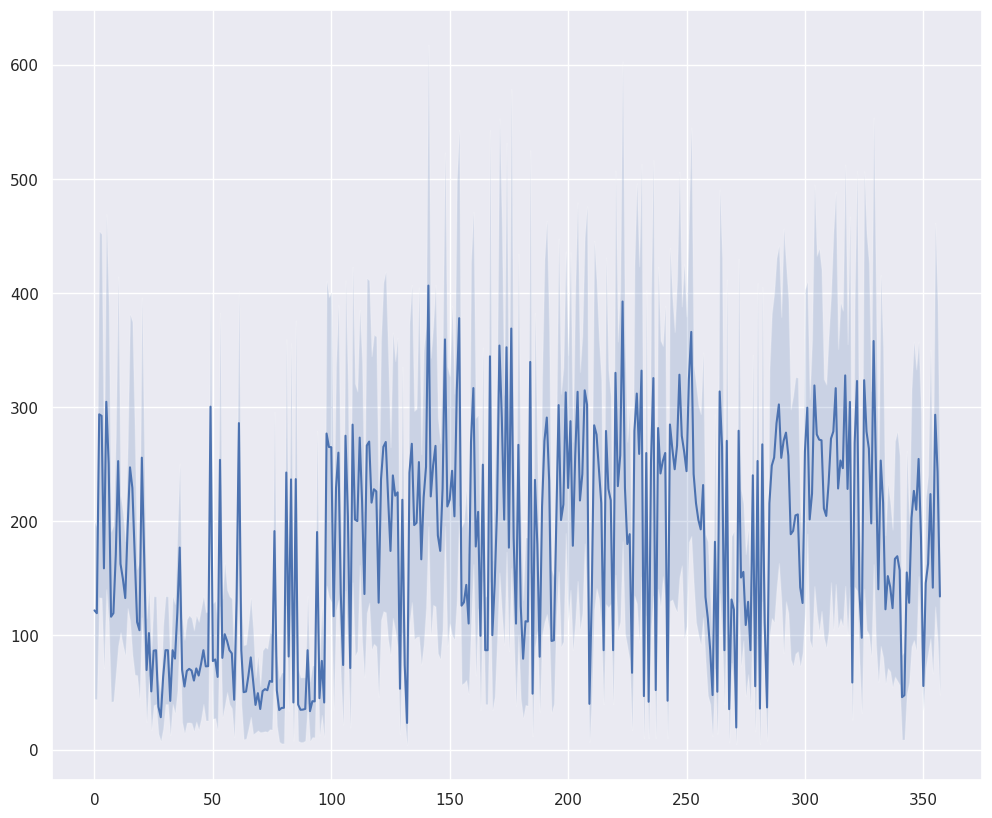

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
plt.figure(figsize=(12, 10))
plt.plot(np.mean(train_data_seq.squeeze(2), axis=0))
plt.fill_between(np.arange(train_data_seq.shape[1]), np.mean(train_data_seq.squeeze(2), axis=0) - np.std(train_data_seq.squeeze(2), axis=0), np.mean(train_data_seq.squeeze(2), axis=0) + np.std(train_data_seq.squeeze(2), axis=0), alpha=0.2)
plt.show()

# Trigger analysis

## Cone pattern

In [22]:
DEVICE = torch.device('cuda:0')
# set attacked variables
spatial_poison_num = max(int(round(train_data_seq.shape[1] * config.alpha_s)), 1)

atk_vars = np.arange(train_data_seq.shape[1])
atk_vars = np.random.choice(atk_vars, size=spatial_poison_num, replace=False)
atk_vars = torch.from_numpy(atk_vars).long().to(DEVICE)
print('shape of attacked_variables', atk_vars.shape)

# load target pattern
target_pattern = config.Target_Pattern
target_pattern = torch.tensor(target_pattern).float().to(DEVICE) * train_std
print(target_pattern)

shape of attacked_variables torch.Size([107])
tensor([18.4551, 25.2422, 40.2460, 55.6397, 40.2460, 25.2422, 18.4551],
       device='cuda:0')


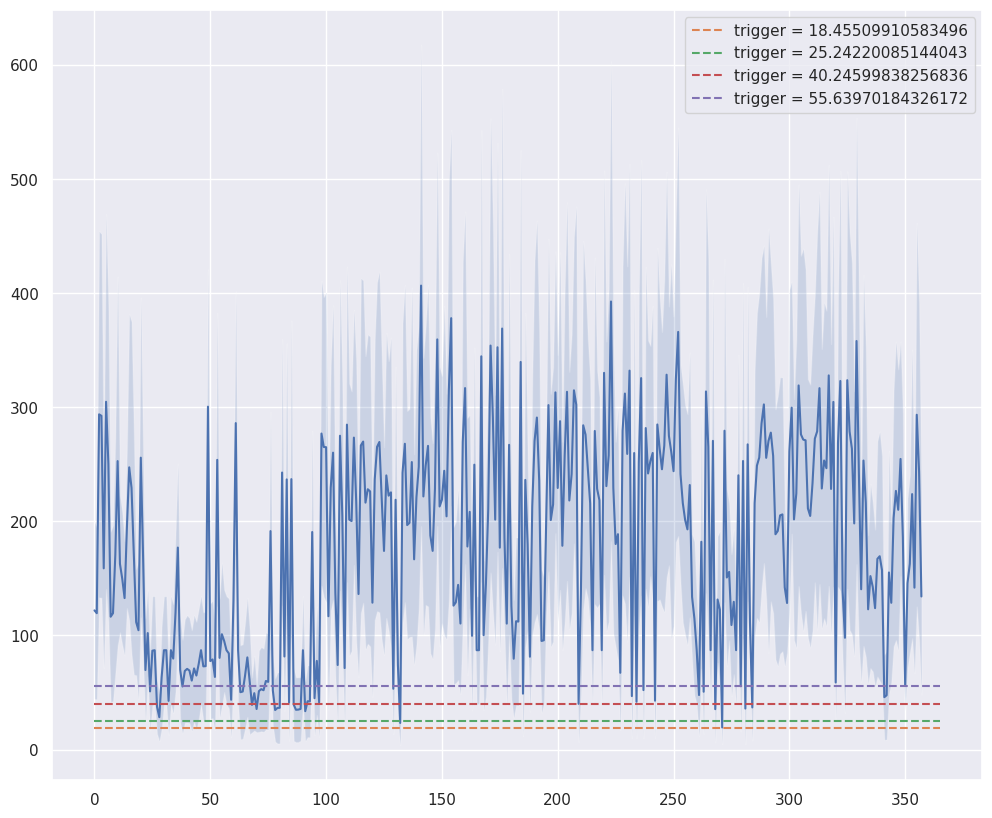

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
plt.figure(figsize=(12, 10))
plt.plot(np.mean(train_data_seq.squeeze(2), axis=0))
plt.fill_between(np.arange(train_data_seq.shape[1]), np.mean(train_data_seq.squeeze(2), axis=0) - np.std(train_data_seq.squeeze(2), axis=0), np.mean(train_data_seq.squeeze(2), axis=0) + np.std(train_data_seq.squeeze(2), axis=0), alpha=0.2)
for pattern in np.unique(target_pattern.detach().cpu().numpy()):
    plt.plot(np.arange(0, 366), [pattern]*366, linestyle='--', label=f'trigger = {round(pattern, 4)}')
plt.legend()
plt.show()

## Up trend

In [5]:
DEVICE = torch.device('cuda:0')
# set attacked variables
spatial_poison_num = max(int(round(train_data_seq.shape[1] * config.alpha_s)), 1)

atk_vars = np.arange(train_data_seq.shape[1])
atk_vars = np.random.choice(atk_vars, size=spatial_poison_num, replace=False)
atk_vars = torch.from_numpy(atk_vars).long().to(DEVICE)
print('shape of attacked_variables', atk_vars.shape)

# load target pattern
target_pattern = config.Target_Pattern
target_pattern = torch.tensor(target_pattern).float().to(DEVICE) * train_std
print(target_pattern)

shape of attacked_variables torch.Size([107])
tensor([20.2891, 29.8054, 39.0619, 40.9392, 42.5854, 50.4700, 51.5097],
       device='cuda:0')


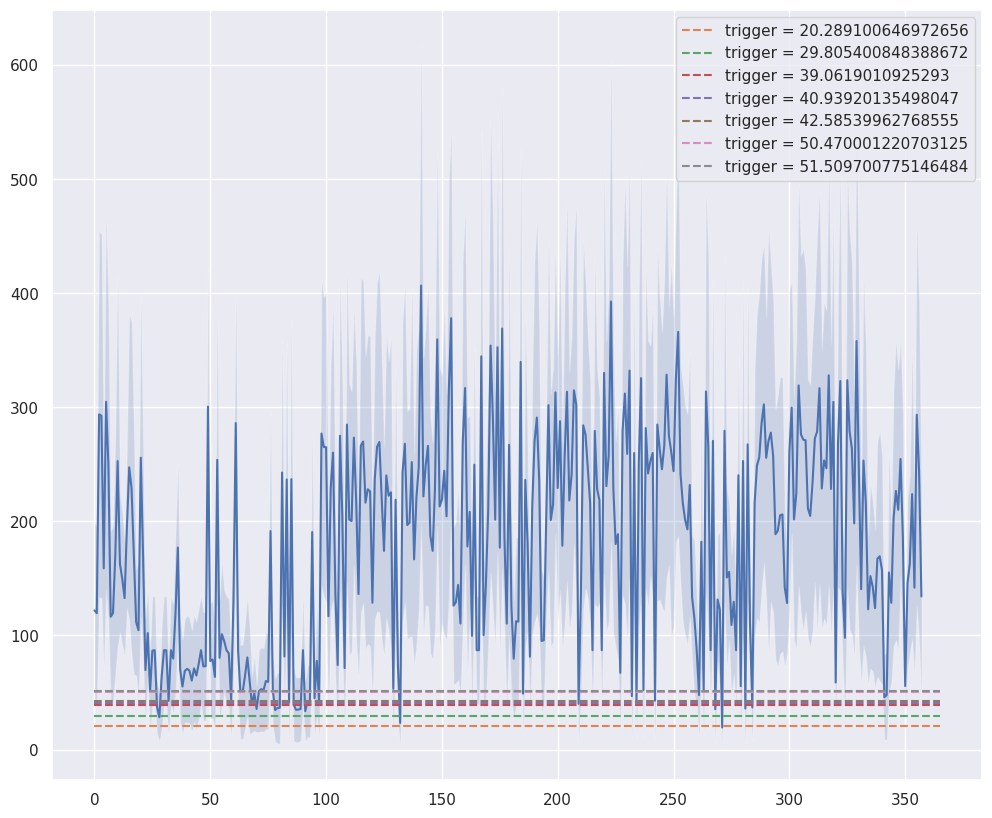

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")
plt.figure(figsize=(12, 10))
plt.plot(np.mean(train_data_seq.squeeze(2), axis=0))
plt.fill_between(np.arange(train_data_seq.shape[1]), np.mean(train_data_seq.squeeze(2), axis=0) - np.std(train_data_seq.squeeze(2), axis=0), np.mean(train_data_seq.squeeze(2), axis=0) + np.std(train_data_seq.squeeze(2), axis=0), alpha=0.2)
for pattern in np.unique(target_pattern.detach().cpu().numpy()):
    plt.plot(np.arange(0, 366), [pattern]*366, linestyle='--', label=f'trigger = {round(pattern, 4)}')
plt.legend()
plt.show()

# synthetic data

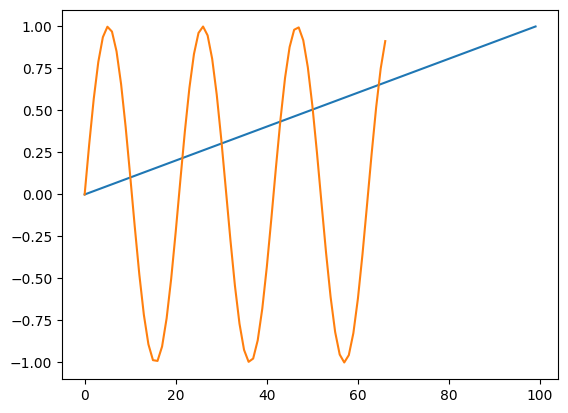

In [1]:
import numpy as np, matplotlib.pyplot as plt
plt.plot(np.linspace(0, 1, 100))
plt.plot(np.sin(np.linspace(0, 20, 67)))
plt.show()

# sine-sin data

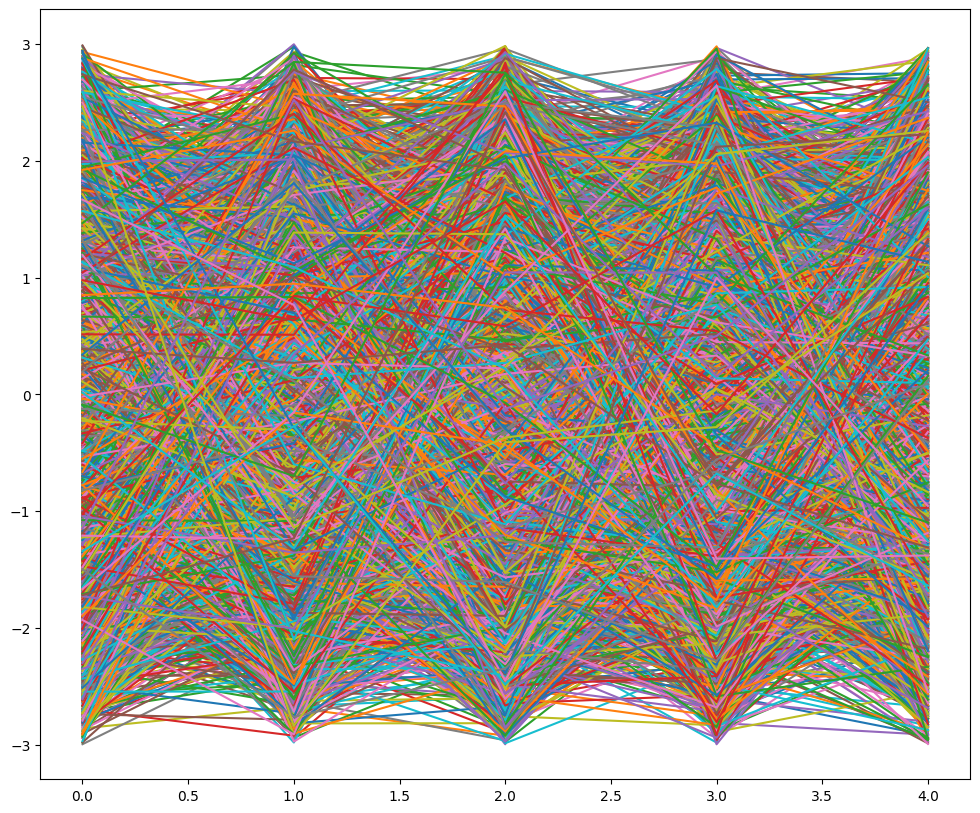

In [21]:
import numpy as np, seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 10))
def sine_sin_data(variate_dim):
    """
    Data synthesized from https://arxiv.org/pdf/2312.11714v2
    """
    variates = np.arange(variate_dim)
    data = []
    for t in range(5000):
        sample = []
        for d in variates:
            alpha = np.random.uniform(1, 3)
            f = np.random.uniform(0.1, 0.15)
            phi = np.random.uniform(0, 2 * np.pi)
            _sample = alpha * np.sin(2 * np.pi * f * t + phi)
            sample.append(_sample)
        data.append(sample)
    data = np.array(data)
    return data

data = sine_sin_data(5)
data.shape
# sns.heatmap(data[:, :1])
for i in range(data.shape[0]):
    plt.plot(data[i])
plt.show()